In [1]:
import pandas as pd
import os
import sys
import json

import seaborn as sns
import numpy as np
import networkx as nx
from pyvis.network import Network

sys.path.append("../functions/")
import networks

In [2]:
from scipy import stats

In [3]:
%load_ext autoreload
%autoreload 2

## Gut microbiome

In [4]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [52]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"__91__e__93__" for met in compounds]

**Load interaction data**

In [53]:
results_abundance = {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_growth_abundance/"):
    if file.endswith(".tsv") and not file.endswith("_growth.tsv"):
        results_abundance[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_abundance/"+file,sep="\t")

results_abundance_df = pd.concat(results_abundance)
results_abundance_df = results_abundance_df.reset_index(drop=True)

In [55]:
results = results_abundance_df.copy()

results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results = results[~results.compound.isin(m9_compounds)]

#### Check that SteadierCom identifies auxotrophies

In [63]:
auxotrophies_gut_df = pd.read_csv("../output/Venturelli2018/auxotrophies.tsv",sep="\t",index_col=[0,1])
auxotrophies_gut_df = auxotrophies_gut_df['0']
results_env = results_abundance_df[(results_abundance_df.receiver!="environment")]

# Find members that are included in the SteadyCom community prediction
members_viable_smetana_gut =list(results_env.receiver.unique())

# Dictionary to store if each (member, metabolite) pair is matched (True/False)
match_essentiality = {}

# Go through each viable member from SMETANA
for member in members_viable_smetana_gut:
    
    # Remove 'mutant_' prefix to match auxotrophy data
    member_aux = member

    # Skip if this mutant isn’t in the auxotrophy data
    if member_aux not in auxotrophies_gut_df.index.get_level_values(0):
        continue
        
    # Get auxotrophic reactions for this mutant
    aux_ser = auxotrophies_gut_df.xs(member_aux)
    aux_rxns = aux_ser.index.values

    # Check each auxotrophic reaction
    for rxn in aux_rxns:
        
        # Get metabolite name from reaction (e.g., R_EX_btn_e → M_btn_e)
        met = "M_" + rxn.split("R_EX_")[1].replace("40","91").replace("41","93")
        
        # Look for rows where the mutant received this metabolite
        sub_df = results_env[
            (results_env.receiver == member) &
            (results_env.compound == met)
        ]
        
        # Save whether a match was found
        match_essentiality[(member, met)] = not sub_df.empty

In [66]:
match_essentiality_gut_df = pd.Series(match_essentiality)
match_essentiality_gut_df

Bacteroides_uniformis_ATCC_8492      M_met_L__91__e__93__      True
                                     M_nac__91__e__93__        True
                                     M_pi__91__e__93__        False
                                     M_trp_L__91__e__93__      True
Faecalibacterium_prausnitzii_A2_165  M_ala_L__91__e__93__      True
                                                              ...  
Desulfovibrio_piger_ATCC_29098       M_nac__91__e__93__        True
                                     M_phenol__91__e__93__     True
                                     M_pi__91__e__93__        False
Prevotella_copri_CB7_DSM_18205       M_met_L__91__e__93__      True
                                     M_pi__91__e__93__        False
Length: 114, dtype: bool

In [67]:
match_essentiality_gut_df[~match_essentiality_gut_df]

Bacteroides_uniformis_ATCC_8492         M_pi__91__e__93__    False
Bacteroides_ovatus_ATCC_8483            M_pi__91__e__93__    False
Bacteroides_thetaiotaomicron_VPI_5482   M_pi__91__e__93__    False
Bacteroides_vulgatus_ATCC_8482          M_pi__91__e__93__    False
Blautia_hydrogenotrophica_DSM_10507     M_pi__91__e__93__    False
Collinsella_aerofaciens_ATCC_25986      M_pi__91__e__93__    False
Clostridium_hiranonis_TO_931_DSM_13275  M_pi__91__e__93__    False
Desulfovibrio_piger_ATCC_29098          M_pi__91__e__93__    False
Prevotella_copri_CB7_DSM_18205          M_pi__91__e__93__    False
dtype: bool

### Load experimental abundances

In [8]:
abundances_exp_list = []

for file in os.listdir("../data/Venturelli2018/generated/communities_steadiercom/"):
    if file.endswith(".tsv"):
        
        abundance = pd.read_csv("../data/Venturelli2018/generated/communities_steadiercom/"+file,sep="\t",header=None)
        
        abundances_exp_list.append(abundance)
        
        
abundances_exp = pd.concat(abundances_exp_list)

In [9]:
abundances_exp.columns = ["community","member","abundance"]

abundances_exp = abundances_exp.set_index(["community","member"])["abundance"]
abundances_exp = abundances_exp.unstack().T
abundances_exp

community,BH-,BO-,BT-,BU-,BV-,CA-,CH-,DP-,EL-,ER-,FP-,NONE,PC-
member,,,,,,,,,,,,,
Bacteroides_ovatus_ATCC_8483,0.1663,NaN,0.2268,0.3229,0.1354,0.1840,0.1840,0.2149,0.4241,0.1343,0.2537,0.1533,0.1927
Bacteroides_thetaiotaomicron_VPI_5482,0.1714,0.2878,NaN,0.2036,0.2148,0.1644,0.1644,0.1476,0.0933,0.1607,0.2162,0.1452,0.1611
Bacteroides_uniformis_ATCC_8492,0.4236,0.2648,0.4698,NaN,0.3968,0.4358,0.4358,0.2646,0.0962,0.3809,0.3736,0.3649,0.3514
Bacteroides_vulgatus_ATCC_8482,0.0454,0.1536,0.0309,0.0912,NaN,0.0342,0.0342,0.0870,0.0660,0.0415,0.0581,0.0140,0.0348
Blautia_hydrogenotrophica_DSM_10507,NaN,0.0089,0.0222,0.0118,0.0140,0.0091,0.0091,0.0197,0.0002,0.0109,0.0038,0.0100,0.0088
Clostridium_hiranonis_TO_931_DSM_13275,0.0100,0.0175,0.0127,0.0097,0.0118,0.0175,NaN,0.0126,0.0024,0.0106,0.0275,0.0212,0.0122
Collinsella_aerofaciens_ATCC_25986,0.0185,0.0250,0.0325,0.0287,0.0266,NaN,0.0002,0.0179,0.0186,0.0255,0.0297,0.0249,0.0199
Desulfovibrio_piger_ATCC_29098,0.0025,0.0020,0.0006,0.0010,0.0010,0.0007,0.0007,NaN,0.0007,0.0006,0.0013,0.0019,0.0011
Eggerthella_lenta_DSM_2243,0.0210,0.0259,0.0168,0.0239,0.0216,0.0112,0.0112,0.0149,NaN,0.0190,0.0185,0.0168,0.0154


### Out degree (frequency)

In [10]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


In [11]:
import matplotlib.pyplot as plt

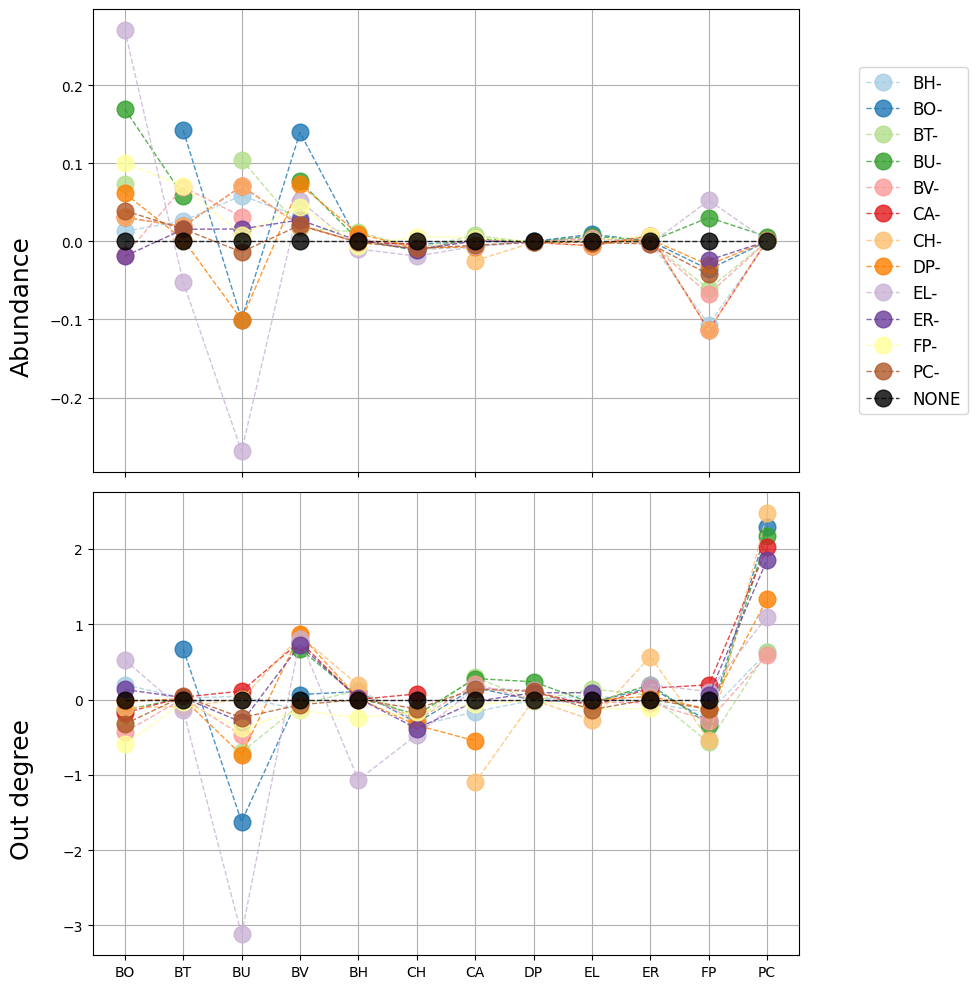

In [12]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = (abundances_exp.T-abundances_exp["NONE"]).T.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
(abundances_exp["NONE"]-abundances_exp["NONE"]).plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("Out degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()
fig.savefig("figures/degree_comm_out.png")


### In degree (frequency)

In [13]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


In [14]:
import matplotlib.pyplot as plt

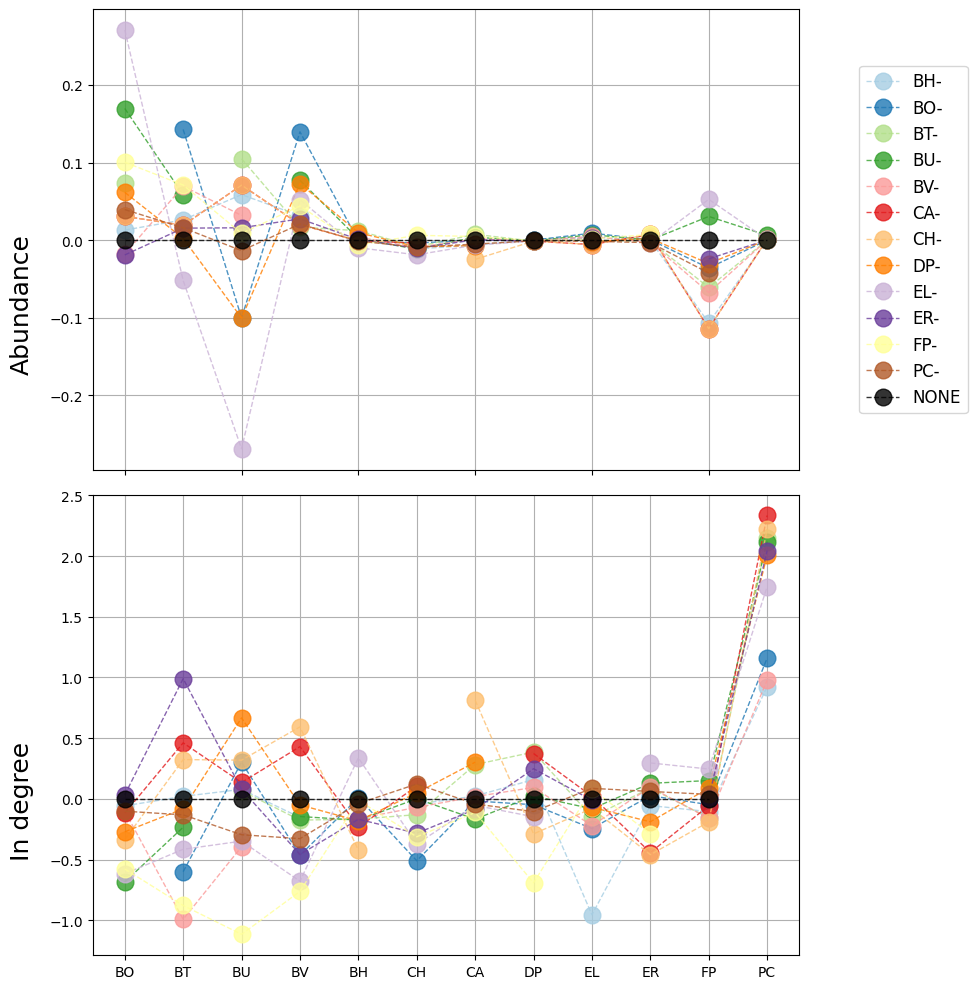

In [15]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = (abundances_exp.T-abundances_exp["NONE"]).T.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
(abundances_exp["NONE"]-abundances_exp["NONE"]).plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("In degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()


### Out degree (frequency)

In [16]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


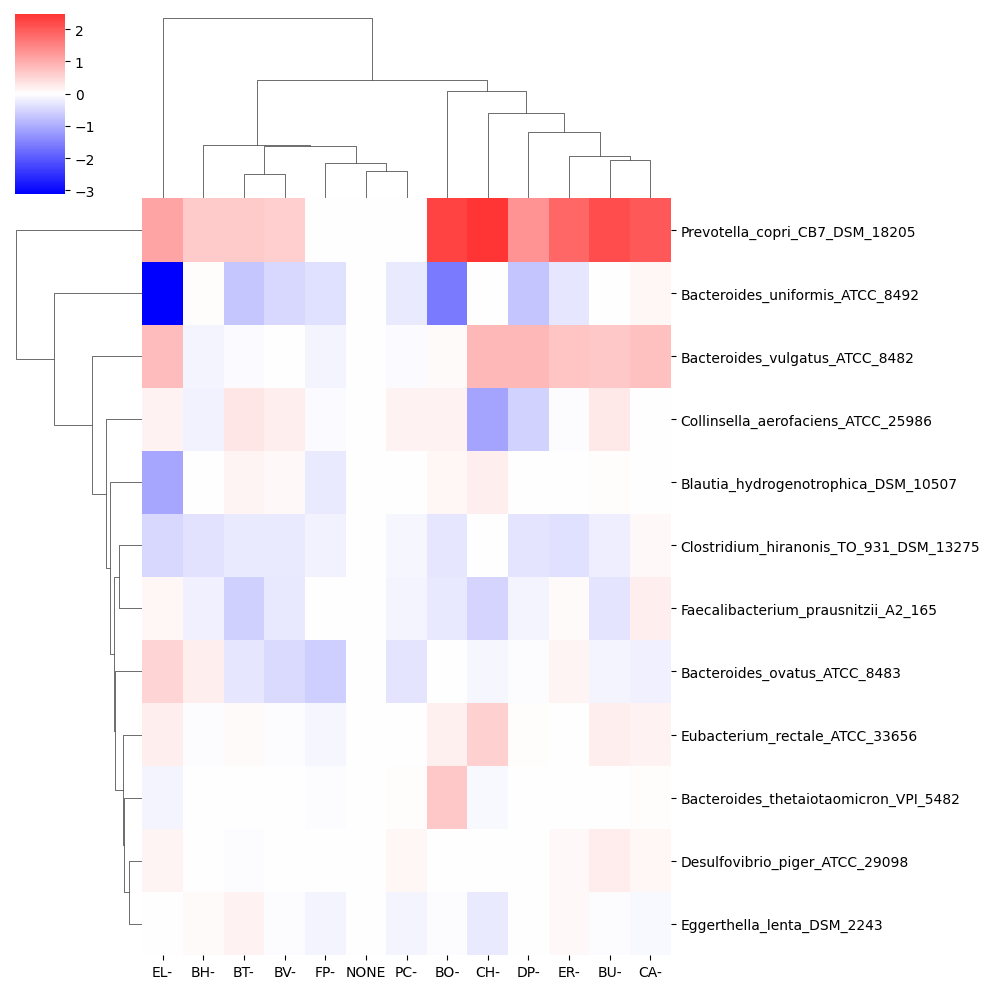

In [17]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### In degree (frequency)

In [18]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


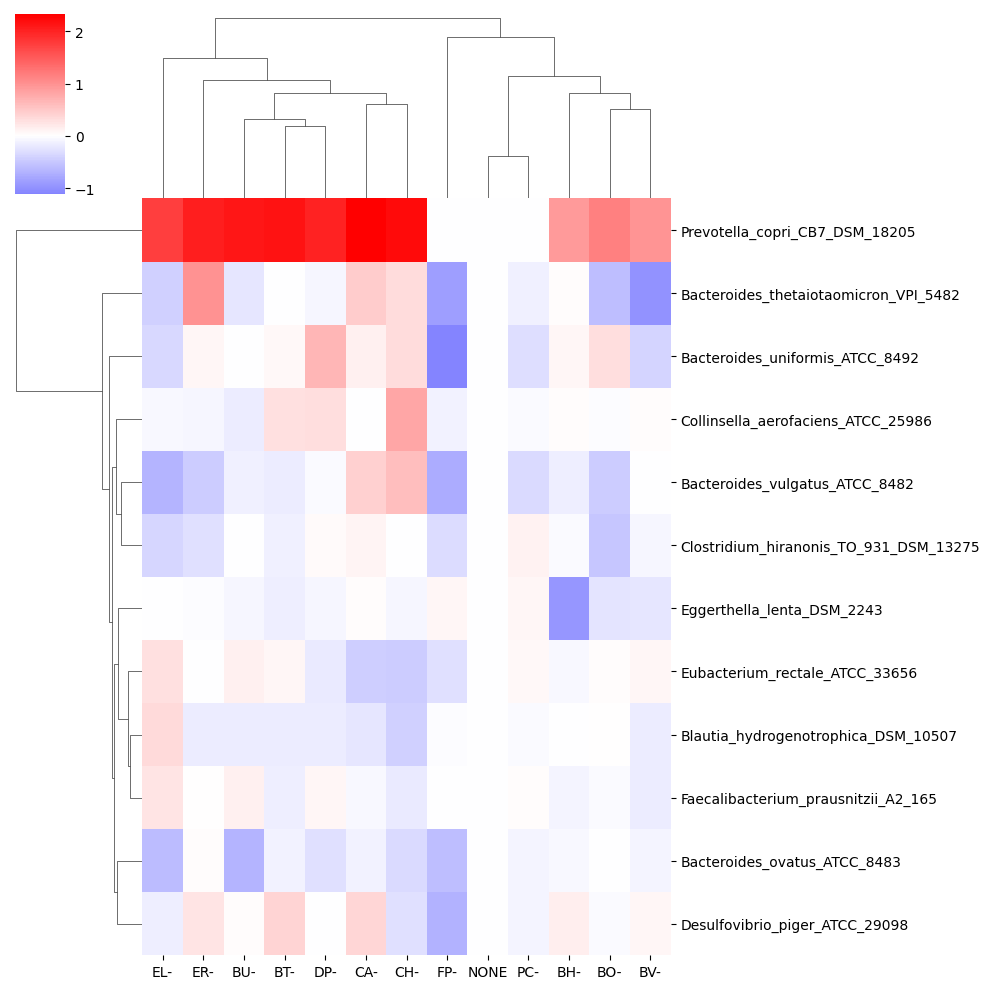

In [19]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### Closeness centrality (frequency)

In [20]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["closeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


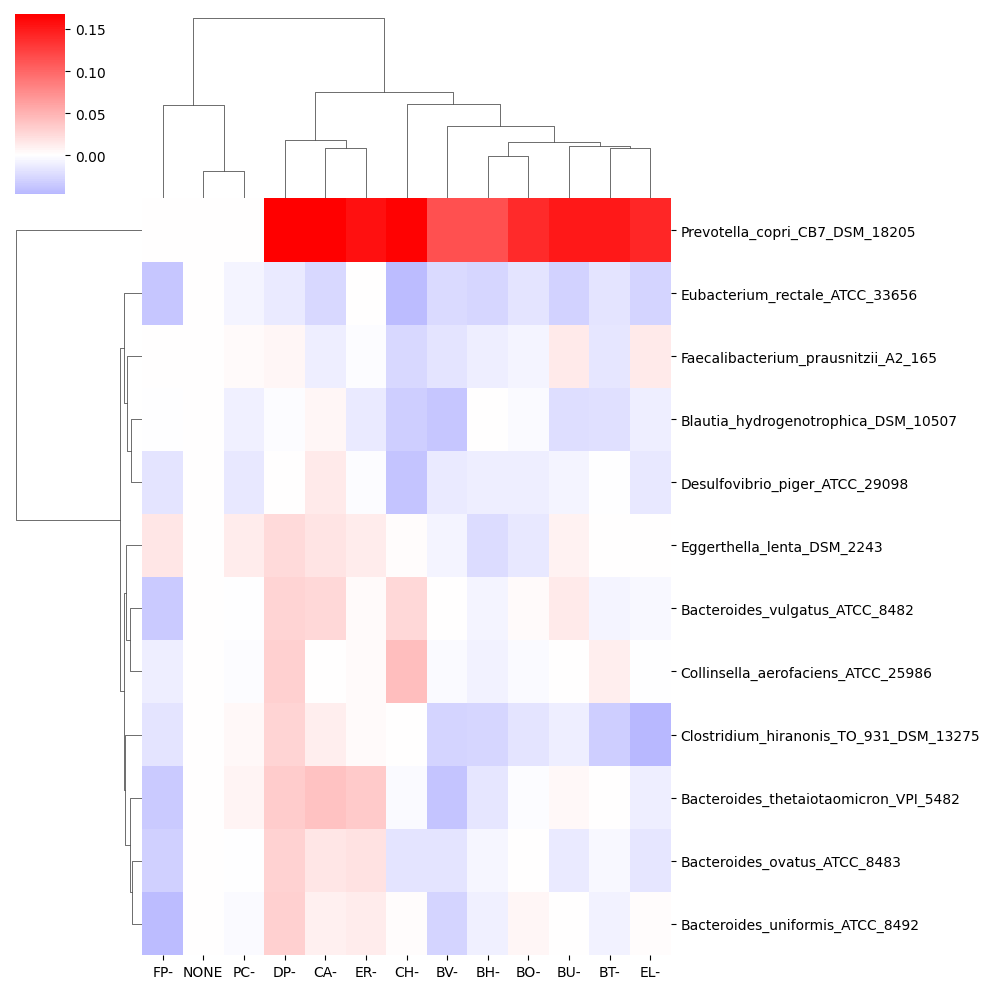

In [21]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### Betweeness centrality (frequency)

In [22]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["betweeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


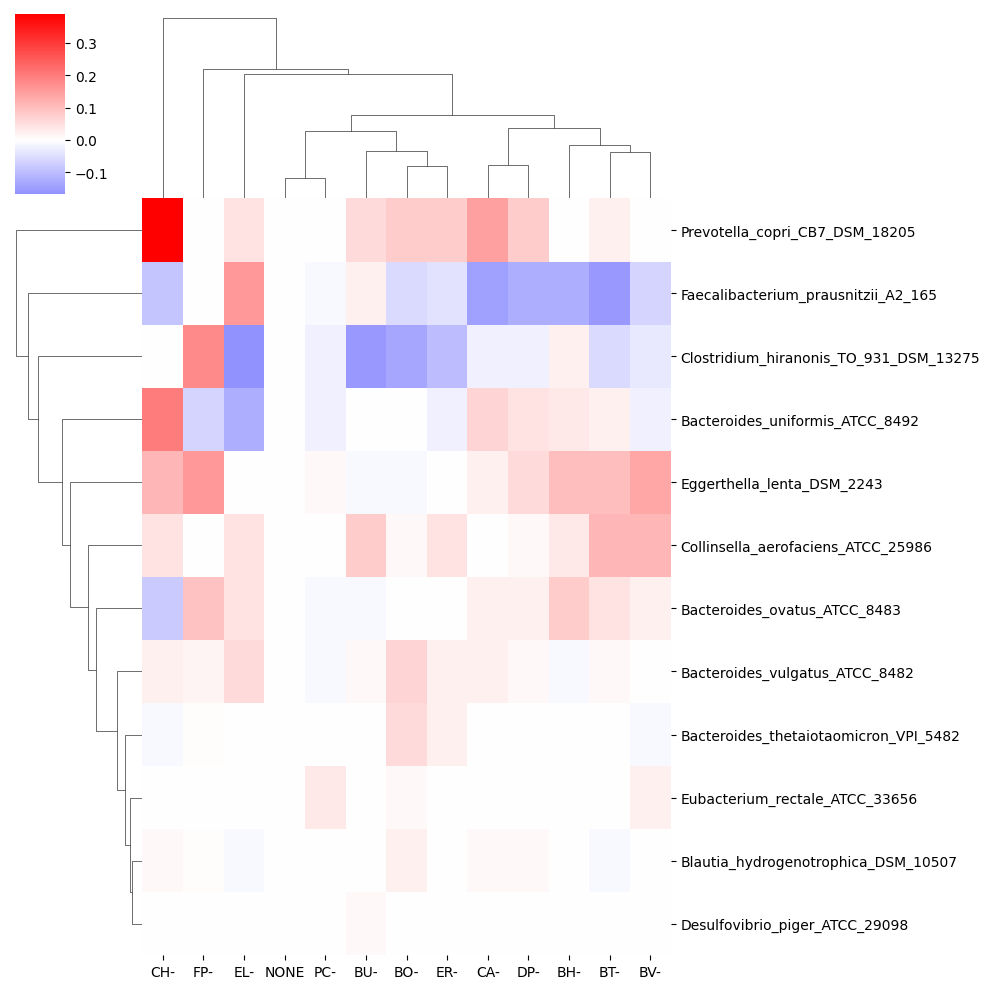

In [23]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

## E.coli

In [5]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"_e" for met in compounds]

**Load interaction data**

In [6]:
results_abundance = {}

results_abundance_df = pd.read_csv("../output/Guillen2021/results_steadiercom/results_abundance/ecoli_mutants.tsv",sep="\t")
results_abundance_df

,donor,receiver,compound,mass_rate,rate,frequency,community,medium
0,environment,mutant_icd,M_glc__D_e,5.392616e-01,2.993314,1.00,Ecoli_mutants,M9
1,environment,mutant_panZ,M_glc__D_e,5.102665e-01,2.832369,1.00,Ecoli_mutants,M9
2,environment,mutant_bioH,M_glc__D_e,3.815244e-01,2.117752,1.00,Ecoli_mutants,M9
3,mutant_icd,environment,M_ac_e,2.155391e-01,3.650490,1.00,Ecoli_mutants,M9
4,mutant_panZ,environment,M_ac_e,1.835567e-01,3.108817,1.00,Ecoli_mutants,M9
...,...,...,...,...,...,...,...,...
134,mutant_icd,mutant_panD,M_pnto__R_e,1.276615e-06,0.000006,0.30,Ecoli_mutants,M9
135,mutant_bioC,mutant_panD,M_pnto__R_e,1.276615e-06,0.000006,0.20,Ecoli_mutants,M9
136,mutant_cysW,mutant_panD,M_pnto__R_e,1.276615e-06,0.000006,0.05,Ecoli_mutants,M9
137,environment,mutant_icd,M_mobd_e,1.753895e-07,0.000001,1.00,Ecoli_mutants,M9


#### Check that SteadierCom identifies auxotrophies

In [7]:
auxotrophies_ecoli_df = pd.read_csv("../output/Guillen2021/auxotrophies.tsv",sep="\t",index_col=[0,1])
auxotrophies_ecoli_df = auxotrophies_ecoli_df['0']
results_env = results_abundance_df[(results_abundance_df.donor!="environment") & (results_abundance_df.receiver!="environment")]

# Find members that are included in the SteadyCom community prediction
members_viable_smetana_ecoli = list(set(list(results_env.receiver.unique())+list(results_env.donor.unique())))

# Dictionary to store if each (member, metabolite) pair is matched (True/False)
match_essentiality = {}

# Go through each viable member from SMETANA
for member in members_viable_smetana_ecoli:
    
    # Remove 'mutant_' prefix to match auxotrophy data
    member_aux = member.split("mutant_")[1]
    
    # Skip if this mutant isn’t in the auxotrophy data
    if member_aux not in auxotrophies_ecoli_df.index.get_level_values(0):
        continue
        
    # Get auxotrophic reactions for this mutant
    aux_ser = auxotrophies_ecoli_df.xs(member_aux)
    aux_rxns = aux_ser.index.values

    # Check each auxotrophic reaction
    for rxn in aux_rxns:
        
        # Get metabolite name from reaction (e.g., R_EX_btn_e → M_btn_e)
        met = "M_" + rxn.split("R_EX_")[1]
        
        # Look for rows where the mutant received this metabolite
        sub_df = results_env[
            (results_env.receiver == member) &
            (results_env.compound == met)
        ]
        
        # Save whether a match was found
        match_essentiality[(member, met)] = not sub_df.empty

In [8]:
pd.Series(match_essentiality)

mutant_bioH  M_btn_e         True
mutant_bioF  M_btn_e         True
mutant_bioC  M_btn_e         True
mutant_panZ  M_pnto__R_e     True
mutant_cysW  M_cys__L_e      True
             M_o2_e         False
mutant_panD  M_pnto__R_e     True
dtype: bool